In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

from parallel_pandas import ParallelPandas
ParallelPandas.initialize(n_cpu=12)

from mpl_toolkits.mplot3d import Axes3D

import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots

import pickle
import os
import glob
import json

import warnings 

from IPython.display import display, HTML

warnings.filterwarnings("ignore")

plt.rcParams["patch.force_edgecolor"] = True

# Чтение данных

In [ ]:
import kagglehub
dataset_path = kagglehub.dataset_download("markhomeless/intellivision-case")

In [ ]:
# Список изображений
imglist = pd.read_csv(os.path.join(dataset_path, "IntelliVision_case", "images_paths.csv"))
imglist.head()

,paths
0,veriwild\1\00001\000001.jpg
1,veriwild\1\00001\000002.jpg
2,veriwild\1\00001\000003.jpg
3,veriwild\1\00001\000004.jpg
4,veriwild\1\00001\000005.jpg


In [ ]:
# Путь к директории с дескрипторами
descriptors_path = os.path.join(dataset_path, "IntelliVision_case", "descriptors")

# Найти все .pickle файлы
pickle_files = glob.glob(os.path.join(descriptors_path, "*.pickle"))

# Сортировать список файлов для детерминированности результата
pickle_files = sorted(pickle_files)
print(f"Найдено {len(pickle_files)} .pickle файлов")

def read_pickle_ndarr(fname):
    with open(fname, 'rb') as pkl_file:
        arr = pickle.load(pkl_file)
        base_name = os.path.basename(fname)
        name = os.path.splitext(base_name)[0]
        print(f'{name:<18}', arr.dtype, arr.shape)
        
        # Конвертируем в float32 для экономии памяти
        if arr.dtype == np.float64:
            return np.array(arr, dtype=np.float32)

        # Защита от нулей с разными знаками (в стандарте IEEE 754 числа +0.0 и -0.0 бинарно различаются)
        arr[arr==0] = 0.0
        return name, arr

# Загрузка исходных данных
data = dict(read_pickle_ndarr(f) for f in pickle_files)

Найдено 4 .pickle файлов
efficientnet-b7    float32 (416314, 2560)
osnet              float32 (416314, 512)
vdc_color          float32 (416314, 128)
vdc_type           float32 (416314, 512)


Исходный набор данных состоит из 4 частей, суммарно имеет 416314 строк и 3712 столбцов. Тип данных float32.

# 1. Очистка и разведочный анализ данных

Признаки, найденные с помощью некоторых моделей, исчисляются тысячами, что довольно много, учитывая общее количество наблюдений.

Как вы понимаете, производить кластеризацию на таком большом количестве признаков, которые были сформированы исходными моделями глубокого обучения, довольно сложно и затратно по времени. К тому же, многие признаки, найденные моделями на изображениях, могут быть сильно скоррелированы между собой.

Понизьте размерность исходных дескрипторов с помощью соответствующих методов. Можно уменьшить размерность входных данных до 100 или 200 признаков — этого будет достаточно, чтобы произвести кластеризацию, однако рекомендуем вам самостоятельно подобрать необходимое количество компонент в новом пространстве признаков.

Также позаботьтесь о масштабе признаков, воспользовавшись стандартизацией и нормализацией. После кластеризации определите, какой вариант масштабирования более успешен для каждого варианта дескрипторов.


## 1.1. Пропуски и бесконечности в данных

In [ ]:
# Проверка на отсутствие пропусков и бесконечностей в данных
for name in data:
    print(f"{name:<18}Отсутствие пропусков и бесконечностей:", np.all(np.isfinite(data[name])).item())

efficientnet-b7   Отсутствие пропусков и бесконечностей: True
osnet             Отсутствие пропусков и бесконечностей: True
vdc_color         Отсутствие пропусков и бесконечностей: True
vdc_type          Отсутствие пропусков и бесконечностей: True


## 1.2. Дубликаты строк и столбцов

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class DataSetDeduplicator(TransformerMixin, BaseEstimator):
    """Удаление дубликатов строк и столбцов"""
    
    def __init__(self, axis=None):
        if axis is not None and axis not in [0, 1]:
            raise ValueError('Параметр axis может быть 0, 1 или None')
        self.axis = None
        if axis in [0, 1]: self.axis = axis
        self.row_dupl_mask = None
        self.col_dupl_mask = None

        
    def fit(self, X, y=None):
        """Ищет дубли и создает маски для удаления"""
        if self.axis == 0 or self.axis is None:
            # Поиск дубликатов строк

            # Создаем "сырой" тип данных, размер которого равен размеру всей строки (в байтах)
            void_dt = np.dtype((np.void, X.dtype.itemsize * X.shape[1]))

            # Делаем view (без копирования), превращаем 2D массив в 1D массив "гигантских" элементов
            arr_view = X.view(void_dt).ravel()

            # Находим индексы первых вхождений уникальных элементов
            _, row_unique_idx = np.unique(arr_view, return_index=True)

            # Формируем маску дубликатов строк
            self.row_dupl_mask = np.ones(X.shape[0], dtype=bool)
            self.row_dupl_mask[row_unique_idx] = False

            self.is_fitted_ = True

        if self.axis == 1 or self.axis is None:
            # Поиск дубликатов столбцов

            # Физически транспонируем массив в памяти
            X_T = np.ascontiguousarray(X.T)

            # Создаем "сырой" тип данных, размер которого равен размеру всего столбца (в байтах)
            void_dt = np.dtype((np.void, X_T.dtype.itemsize * X_T.shape[1]))

            # Делаем view (без копирования), превращаем 2D массив в 1D массив "гигантских" элементов
            arr_view = X_T.view(void_dt).ravel()

            # Находим индексы первых вхождений уникальных элементов
            _, col_unique_idx = np.unique(arr_view, return_index=True)

            # Формируем маску дубликатов
            self.col_dupl_mask = np.ones(X.shape[1], dtype=bool)
            self.col_dupl_mask[col_unique_idx] = False

            self.is_fitted_ = True
    
        return self

    
    def transform(self, X):
        """Дедупликация по найденным маскам"""
        check_is_fitted(self, attributes=['is_fitted_'])

        if self.row_dupl_mask is not None and self.col_dupl_mask is not None:
            # Дедупликация по обеим осям
            return X[np.ix_(~self.row_dupl_mask, ~self.col_dupl_mask)]
        elif self.row_dupl_mask is not None:
            # Дедупликация по строкам
            return X[~self.row_dupl_mask, :]
        elif self.col_dupl_mask is not None:
            # Дедупликация по столбцам
            return X[:, ~self.col_dupl_mask]
        return None

In [ ]:
%%time

# Поиск дубликатов среди строк и столбцов
Deduplicator = dict()
for name in data:
    Deduplicator[name] = DataSetDeduplicator()
    Deduplicator[name].fit(data[name])
    duplicate_rows_count = Deduplicator[name].row_dupl_mask.sum()
    duplicate_cols_count = Deduplicator[name].col_dupl_mask.sum()
    print(f"{name:<18}Дубликатов строк: {duplicate_rows_count:>5},\tДубликатов столбцов: {duplicate_cols_count:>5}")

efficientnet-b7   Дубликатов строк:     0,	Дубликатов столбцов:     0
osnet             Дубликатов строк:  1208,	Дубликатов столбцов:     0
vdc_color         Дубликатов строк:  1208,	Дубликатов столбцов:     0
vdc_type          Дубликатов строк:  1208,	Дубликатов столбцов:     0
CPU times: total: 28.7 s
Wall time: 33.6 s


In [ ]:
# Дубликаты строк в osnet, vdc_color и vdc_type одинаковые
print((Deduplicator['osnet'].row_dupl_mask == Deduplicator['vdc_color'].row_dupl_mask).all())
print((Deduplicator['vdc_color'].row_dupl_mask == Deduplicator['vdc_type'].row_dupl_mask).all())

True
True


## 1.3. Константные признаки 

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted

class DataSetConstFeaturesEraser(TransformerMixin, BaseEstimator):
    """Удаляет константные признаки по их std или cv, сравнивая с порогом отсечения threshold"""

    def __init__(self, threshold=1e-3, method='cv'):
        if method not in ['cv', 'std']:
            raise ValueError("Параметр method принимает значения 'cv' или 'std'")
        self.threshold = threshold
        self.method = method
        self.features_std = None
        self.features_mean = None
        self.features_cv_abs = None
        
    def fit(self, X, y=None):
        """Создает маску столбцов для удаления"""  
        # Стандартное отклонение по столбцам (axis=0)
        self.features_std = np.std(X, axis=0)
        self.features_mean = np.mean(X, axis=0)
        # Коэффициент вариации (абсолютное значение) показывает относительный разброс данных
        self.features_cv_abs = np.abs(self.features_std / (self.features_mean + 1e-8)) # Защита от деления на 0  

        # Находим индексы, где std меньше порога
        self.constant_std_mask = self.features_std < self.threshold

        # Находим индексы, где cv меньше порога
        self.constant_cv_mask = self.features_cv_abs < self.threshold

        self.is_fitted_ = True
        return self
    
    def transform(self, X):
        """Удаление столбцов по маске"""
        check_is_fitted(self, attributes=['is_fitted_'])

        if self.method == 'cv':
            # По коэффициенту вариации
            return X[:, ~self.constant_cv_mask]
        elif self.method == 'std':
            # По стандартному отклонению
            return X[:, ~self.constant_std_mask]
        return None

In [ ]:
%%time

# Порог отсечения константных признаков
const_threshold = 1e-3

# Поиск константных признаков
ConstEraser = dict()
for name in data:
    ConstEraser[name] = DataSetConstFeaturesEraser(threshold=const_threshold)
    ConstEraser[name].fit(data[name])
    const_feature_std_cnt = ConstEraser[name].constant_std_mask.sum()
    const_feature_cv_cnt = ConstEraser[name].constant_cv_mask.sum()
    print(f"{name:<18}Порог: {const_threshold}. Константных признаков: {const_feature_std_cnt:>3} (std=0), {const_feature_cv_cnt:>3} (cv=0)")

efficientnet-b7   Порог: 0.001. Константных признаков:   0 (std=0),   0 (cv=0)
osnet             Порог: 0.001. Константных признаков:   1 (std=0),   1 (cv=0)
vdc_color         Порог: 0.001. Константных признаков:   0 (std=0),   0 (cv=0)
vdc_type          Порог: 0.001. Константных признаков:   0 (std=0),   0 (cv=0)
CPU times: total: 6.31 s
Wall time: 6.33 s


In [ ]:
# Масштаб признаков efficientnet-b7

percentiles = np.arange(0.1, 1.0, 0.1)
# Важен разброс вокруг среднего, т.к. алгоритмы PCA и SVD максимизируют абсолютную дисперсию
# Если абсолютное значение CV близко к нулю, то признак практически константный и не несет полезной информации.
pd.DataFrame({
    'std': ConstEraser['efficientnet-b7'].features_std,
    'cv': ConstEraser['efficientnet-b7'].features_cv_abs
}).describe(percentiles=percentiles).rename_axis('efficientnet-b7')

,std,cv
efficientnet-b7,,
count,2560.000000,2560.000000
mean,0.184031,4.986484
std,0.010602,1.706212
min,0.142060,2.235016
10%,0.170227,3.355590
20%,0.175210,3.699207
30%,0.178518,3.997000
40%,0.181459,4.283016
50%,0.184166,4.611895


In [ ]:
# Масштаб признаков osnet

percentiles = np.arange(0.1, 1.0, 0.1)
# Важен разброс вокруг среднего, т.к. алгоритмы PCA и SVD максимизируют абсолютную дисперсию
# Если абсолютное значение CV близко к нулю, то признак практически константный и не несет полезной информации.
pd.DataFrame({
    'std': ConstEraser['osnet'].features_std,
    'cv': ConstEraser['osnet'].features_cv_abs
}).describe(percentiles=percentiles).rename_axis('osnet')

,std,cv
osnet,,
count,512.000000,512.000000
mean,0.924584,1.602783
std,0.539918,1.014855
min,0.000000,0.000000
10%,0.354416,0.722262
20%,0.477939,0.863520
30%,0.612744,0.992832
40%,0.705732,1.179347
50%,0.821600,1.316571


In [ ]:
# Масштаб признаков vdc_color

percentiles = np.arange(0.1, 1.0, 0.1)
# Важен разброс вокруг среднего, т.к. алгоритмы PCA и SVD максимизируют абсолютную дисперсию
# Если абсолютное значение CV близко к нулю, то признак практически константный и не несет полезной информации.
pd.DataFrame({
    'std': ConstEraser['vdc_color'].features_std,
    'cv': ConstEraser['vdc_color'].features_cv_abs
}).describe(percentiles=percentiles).rename_axis('vdc_color')

,std,cv
vdc_color,,
count,128.000000,128.000000
mean,0.247507,3.977781
std,0.085438,19.422384
min,0.148492,0.211494
10%,0.183504,0.270369
20%,0.191363,0.309423
30%,0.202693,0.339979
40%,0.212409,0.386544
50%,0.219179,0.448112


In [ ]:
# Масштаб признаков vdc_type

percentiles = np.arange(0.1, 1.0, 0.1)
# Важен разброс вокруг среднего, т.к. алгоритмы PCA и SVD максимизируют абсолютную дисперсию
# Если абсолютное значение CV близко к нулю, то признак практически константный и не несет полезной информации.
pd.DataFrame({
    'std': ConstEraser['vdc_type'].features_std,
    'cv': ConstEraser['vdc_type'].features_cv_abs
}).describe(percentiles=percentiles).rename_axis('vdc_type')

,std,cv
vdc_type,,
count,512.000000,512.000000
mean,0.122024,1.049890
std,0.045397,0.436911
min,0.024337,0.404937
10%,0.064449,0.633831
20%,0.084114,0.725136
30%,0.097022,0.777655
40%,0.105784,0.877175
50%,0.117863,0.950754


## 1.4. Мультиколлинеарность

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_is_fitted
import scipy.stats as stats

class DataSetCorrelationCleaner(TransformerMixin, BaseEstimator):
    """
    Устраняет мультиколлинеарность, сравнивая коэффициенты корреляции с порогом отсечения threshold.
    Из пары сильно скоррелированных признаков удаляется тот, у которого скошенность выше.

    Параметр draw_diagrams управляет сбором дополнительной статистики для построения диаграмм 
    (может занимать значительное время).
    """

    def __init__(self, threshold=0.9, method='pearson', draw_diagrams=True):
        if method not in ['pearson', 'spearman']:
            raise ValueError("Параметр method принимает значения 'pearson' или 'spearman'.")
        # print(f'DataSetCorrelationCleaner: {threshold=}, {method=}')
        self.threshold = threshold
        self.method = method
        self.draw_diagrams = draw_diagrams
        self.X = None
        self.features_skew = None

        self.pearson_corr_matrix = None
        self.pearson_high_corr_pairs = None
        self.pearson_drop_mask = None

        self.spearman_corr_matrix = None
        self.spearman_high_corr_pairs = None
        self.spearman_drop_mask = None

        self.drop_mask = None


    def skew(self, X):
        """Коэффициент скошенности (Skewness)"""
        return stats.skew(X, axis=0, nan_policy='omit')


    def pearson_correlation(self, X):
        """Возвращает матрицу корреляций Пирсона"""
        return np.corrcoef(X, rowvar=False)


    def spearman_correlation(self, X):
        """Возвращает матрицу корреляций Спирмена"""

        # Переводим в ранги
        ranks = stats.rankdata(X, axis=0) 

        # Считаем корреляцию Пирсона по рангам (это и есть Спирмен)
        return self.pearson_correlation(ranks)


    def set_threshold_(self, corr_matrix, threshold, features_skew):
        """
        Вспомогательная функция для пересчета списка сильно скоррелированных признаков. 
        Возвращает массив с парами индексов для признаков и маску для их удаления.
        """
        # Создаем маску для верхнего треугольника (исключая диагональ)
        upper_tri = np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1)

        # Находим признаки с корреляцией (абсолютные значения) выше порога
        high_corr_mask = (np.abs(corr_matrix) > threshold) & upper_tri

        # Получаем индексы пар признаков (i, j)
        i_indices, j_indices = np.where(high_corr_mask)
        high_corr_pairs = np.hstack([i_indices.reshape(-1, 1), j_indices.reshape(-1, 1)])

        # Берем абсолютные значения скошенности
        skew_abs = np.abs(features_skew)
        skew_i = skew_abs[i_indices]
        skew_j = skew_abs[j_indices]

        # Выбираем из каждой пары признак с БОЛЬШЕЙ скошенностью.
        # Если скошенность i >= j, то удаляем признак i, иначе - признак j.
        to_drop = np.where(skew_i >= skew_j, i_indices, j_indices)

        # Убираем дубликаты (если один и тот же признак скоррелирован с несколькими)
        drop_indices = np.unique(to_drop)

        drop_mask = np.full(corr_matrix.shape[1], False, dtype=np.bool_)
        drop_mask[drop_indices] = True

        return high_corr_pairs, drop_mask


    def print_report(self):
        """
        Выводит отчет о значении порога, количестве признаков с высокой корреляцией, подлежащих удалению.
        """
        print(f'Порог {self.threshold}')
        if self.pearson_drop_mask is not None:
            print(f"Метод Пирсона. Признаков с высокой корреляцией: {self.pearson_drop_mask.sum()}")
        if self.spearman_drop_mask is not None:
            print(f"Метод Спирмена. Признаков с высокой корреляцией: {self.spearman_drop_mask.sum()}")
        return self


    def set_threshold(self, threshold):
        """
        Устанавливает порог для абсолютного значения корреляции. При необходимости пересчитывает 
        список сильно скоррелированных признаков и маску для их удаления.
        """
        if threshold < 0.0 or threshold > 1.0:
            raise ValueError('Порог абсолютного значения корреляции должен быть в пределах [0.0, 1.0]')
        
        if threshold != self.threshold and self.is_fitted_:
            # Пересчитать свойства, если меняется порог для уже обученного трансформера
            if self.method == 'pearson' or self.draw_diagrams:
                self.pearson_high_corr_pairs, self.pearson_drop_mask = self.set_threshold_(
                    self.pearson_corr_matrix,
                    threshold,
                    self.features_skew
                )
            if self.method == 'spearman' or self.draw_diagrams:
                self.spearman_high_corr_pairs, self.spearman_drop_mask = self.set_threshold_(
                    self.spearman_corr_matrix,
                    threshold,
                    self.features_skew
                )

        self.threshold = threshold
        return self


    def fit(self, X, y=None):
        """Создает маску столбцов для удаления"""  
        self.X = X

        # Коэффициент скошенности (Skewness)
        self.features_skew = self.skew(X)

        # Корреляции
        if self.method == 'pearson' or self.draw_diagrams:
            self.pearson_corr_matrix = self.pearson_correlation(X)
            self.pearson_high_corr_pairs, self.pearson_drop_mask = self.set_threshold_(
                self.pearson_corr_matrix,
                self.threshold,
                self.features_skew
            )
        if self.method == 'spearman' or self.draw_diagrams:
            self.spearman_corr_matrix = self.spearman_correlation(X)
            self.spearman_high_corr_pairs, self.spearman_drop_mask = self.set_threshold_(
                self.spearman_corr_matrix,
                self.threshold,
                self.features_skew
            )
             
        if self.method == 'pearson':
            self.drop_mask = self.pearson_drop_mask
        else:
            self.drop_mask = self.spearman_drop_mask
            
        self.is_fitted_ = True
        return self

    
    def transform(self, X):
        """Удаление столбцов по маске"""
        check_is_fitted(self, attributes=['is_fitted_'])

        if self.method == 'pearson':
            return X[:, ~self.pearson_drop_mask]
        elif self.method == 'spearman':
            return X[:, ~self.spearman_drop_mask]
        return None


    def get_pair_indices_for_diagram(self, method):
        """
        Возвращает пару индексов столбцов, если draw_diagrams был установлен в True.
        Один признак выбирается из множества найденных методом method, а другой - из множества альтернативного метода. 
        Из выбора исключается область пересечения двух множеств.
        Из нескольких пар выбирается вариант с максимальной разницей между двумя методами корреляции.
        Если пару найти невозможно, возвращает None, None.
        """
        check_is_fitted(self, attributes=['is_fitted_'])

        if not self.draw_diagrams:
            return None, None

        # Выбрать все пары индексов с сильной корреляционной связью по методу method Спирмену
        if method == 'pearson':
            # Выбрать все пары индексов с сильной корреляционной связью
            p_features_idx = self.pearson_high_corr_pairs

            # Проверить на вхождение в область пересечения множеств
            p_features_mask = np.any(np.isin(p_features_idx, self.spearman_high_corr_pairs.flatten()), axis=1)

        elif method == 'spearman':
            # Выбрать все пары индексов с сильной корреляционной связью
            p_features_idx = self.spearman_high_corr_pairs

            # Проверить на вхождение в область пересечения множеств
            p_features_mask = np.any(np.isin(p_features_idx, self.pearson_high_corr_pairs.flatten()), axis=1)

        else:
            raise ValueError("Параметр method принимает значения 'pearson' или 'spearman'.")

        # Выбрать такие пары индексов, что оба отсутствуют в списке другого метода
        if np.all(p_features_mask):
            return None, None
        pair_feature_idx = p_features_idx[~p_features_mask, :]

        # Найти вариант с максимальной разницей между двумя методами корреляции
        pearson_pair = self.pearson_corr_matrix[pair_feature_idx[:,0], pair_feature_idx[:,1]]
        spearman_pair = self.spearman_corr_matrix[pair_feature_idx[:,0], pair_feature_idx[:,1]]
        method_diff = np.abs(pearson_pair - spearman_pair)
        idx1, idx2 = tuple(pair_feature_idx[np.argmax(method_diff), :])

        return idx1, idx2
    

    def draw_subplot_(self, idx1, idx2, frac=1.0, ax=None):
        """Вспомогательная функция отрисовки субграфика на заданных осях"""
        df_pair = pd.DataFrame(
            self.X[:, [idx1, idx2]],
            columns=[f'Feature{idx1}', f'Feature{idx2}']
        ).sample(frac=frac, random_state=42)
        
        sns.regplot(
            data=df_pair,
            x=df_pair.columns[0],
            y=df_pair.columns[1],
            ax=ax,
            scatter_kws={'alpha': 0.1, 's': 4},
            line_kws={'color': 'tab:red'}
        )
        
        ax.set_title('Корреляция и линейная регрессия признаков')
        pearson = self.pearson_corr_matrix[idx1, idx2]
        spearman = self.spearman_corr_matrix[idx1, idx2]
        text = f'{pearson=:.3f}\n{spearman=:.3f}'
        ax.text(
            0.35, 0.95,
            text,
            transform=ax.transAxes,
            fontsize=10,
            verticalalignment='top',
            horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='gray')
        )

    
    def draw_corr_diagram(self, frac=1.0, method=None):
        """
        Рисует одну диаграмму рассеяния.
        Из списка высоко скоррелированных признаков выбирается пара с минимальной корреляцией.
        По умолчанию ссылается на метод корреляции, заданный при инициализации.
        """
        check_is_fitted(self, attributes=['is_fitted_'])
        if method is None:
            method = self.method

        if method == 'pearson' and len(self.pearson_high_corr_pairs) > 0:
            pair_feature_idx = self.pearson_high_corr_pairs
            corr_matrix = self.pearson_corr_matrix
        elif method == 'spearman' and len(self.spearman_high_corr_pairs) > 0:
            pair_feature_idx = self.spearman_high_corr_pairs
            corr_matrix = self.spearman_corr_matrix
        else:
            return None

        # Выбрать по минимальной корреляции
        corr = corr_matrix[pair_feature_idx[:,0], pair_feature_idx[:,1]]
        idx1, idx2 = tuple(pair_feature_idx[np.argmin(corr), :])

        # Отрисовать диаграмму
        fig, ax = plt.subplots(1, 1, figsize=(5.5, 5))
        self.draw_subplot_(idx1, idx2, frac, ax)
        return ax


    def draw_cross_corr_diagram(self, frac=1.0):
        """
        Рисует одну или две диаграммы рассеяния для демонстрации различий в двух методах вычисления корреляций.
        Используются только высоко скоррелированные пары признаков.
        Параметр frac задает долю точек в столбце, которые участвуют для отображения.
        Возвращает пару axis, из которых любой может быть None, если диаграмму построить невозможно.
        """
        check_is_fitted(self, attributes=['is_fitted_'])
        if not self.draw_diagrams:
            raise Exception('Параметр draw_diagrams установлен в False.')
        if self.pearson_drop_mask.sum()==0 or self.spearman_drop_mask.sum()==0:
            print('draw_cross_corr_diagram: Нет признаков для удаления.')
            return None, None
        
        pearson_idx1, pearson_idx2 = self.get_pair_indices_for_diagram('pearson')
        spearman_idx1, spearman_idx2 = self.get_pair_indices_for_diagram('spearman')
        if pearson_idx1 is None and spearman_idx1 is None:
            if self.pearson_drop_mask.sum() >= self.spearman_drop_mask.sum():
                print('draw_cross_corr_diagram: Множество признаков по методу Пирсона поглощает результат по Спирману.')
            else:
                print('draw_cross_corr_diagram: Множество признаков по методу Спирмана поглощает результат по Пирсону.')
            ax = self.draw_corr_diagram(frac)
            return ax, None
        
        if pearson_idx1 is not None and spearman_idx1 is not None:
            _, axes = plt.subplots(1, 2, figsize=(10, 5))
            self.draw_subplot_(pearson_idx1, pearson_idx2, frac, axes[0])
            self.draw_subplot_(spearman_idx1, spearman_idx2, frac, axes[1])
            plt.tight_layout()
            return axes[0], axes[1]

        else:
            _, ax = plt.subplots(1, 1, figsize=(5.5, 5))
            if pearson_idx1 is not None:
                self.draw_subplot_(pearson_idx1, pearson_idx2, frac, ax)
            else:
                self.draw_subplot_(spearman_idx1, spearman_idx2, frac, ax)
            return ax, None


In [ ]:
# Порог отсечения признаков по корреляции
corr_threshold = 0.90

CorrCleaner = dict()

In [ ]:
%%time
CorrCleaner['efficientnet-b7'] = DataSetCorrelationCleaner(threshold=corr_threshold)
CorrCleaner['efficientnet-b7'].fit(data['efficientnet-b7']).print_report();

Порог 0.9
Метод Пирсона. Признаков с высокой корреляцией: 0
Метод Спирмена. Признаков с высокой корреляцией: 0
CPU times: total: 10min 39s
Wall time: 4min 57s


In [ ]:
CorrCleaner['efficientnet-b7'].set_threshold(corr_threshold);

In [ ]:
%%time
CorrCleaner['osnet'] = DataSetCorrelationCleaner(threshold=corr_threshold)
CorrCleaner['osnet'].fit(data['osnet']).print_report();

Порог 0.9
Метод Пирсона. Признаков с высокой корреляцией: 0
Метод Спирмена. Признаков с высокой корреляцией: 0
CPU times: total: 1min
Wall time: 32.7 s


In [ ]:
%%time
CorrCleaner['vdc_color'] = DataSetCorrelationCleaner(threshold=corr_threshold)
CorrCleaner['vdc_color'].fit(data['vdc_color']).print_report()
CorrCleaner['vdc_color'].set_threshold(0.95).print_report();

Порог 0.9
Метод Пирсона. Признаков с высокой корреляцией: 5
Метод Спирмена. Признаков с высокой корреляцией: 4
Порог 0.95
Метод Пирсона. Признаков с высокой корреляцией: 0
Метод Спирмена. Признаков с высокой корреляцией: 0
CPU times: total: 12 s
Wall time: 9.45 s


draw_cross_corr_diagram: Множество признаков по методу Пирсона поглощает результат по Спирману.


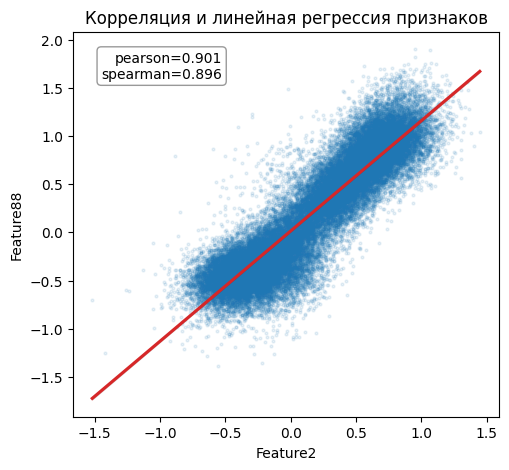

In [ ]:
CorrCleaner['vdc_color'].set_threshold(corr_threshold) # Восстановить threshold=corr_threshold
CorrCleaner['vdc_color'].draw_cross_corr_diagram(frac=0.1);

In [ ]:
%%time
CorrCleaner['vdc_type'] = DataSetCorrelationCleaner(threshold=corr_threshold)
CorrCleaner['vdc_type'].fit(data['vdc_type']).print_report();

Порог 0.9
Метод Пирсона. Признаков с высокой корреляцией: 164
Метод Спирмена. Признаков с высокой корреляцией: 116
CPU times: total: 1min 10s
Wall time: 39.9 s


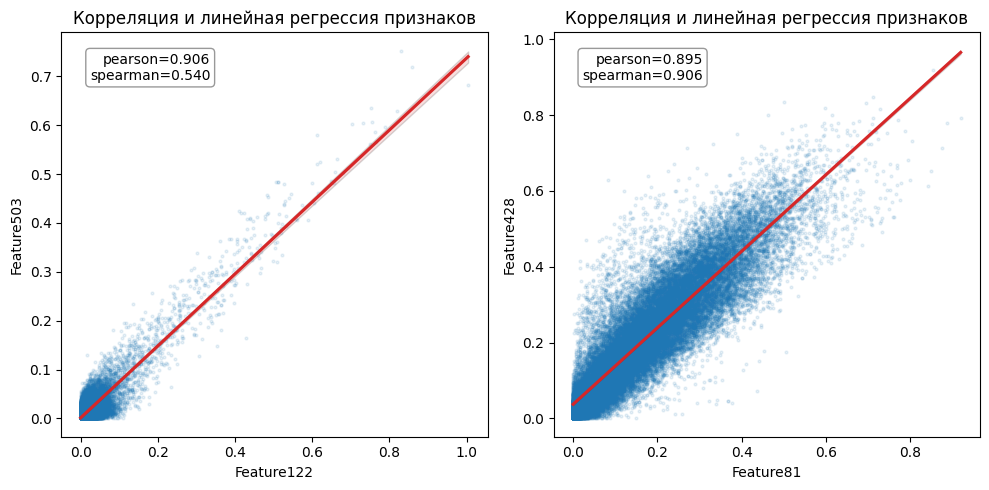

In [ ]:
CorrCleaner['vdc_type'].draw_cross_corr_diagram(frac=0.1);

Порог 0.95
Метод Пирсона. Признаков с высокой корреляцией: 62
Метод Спирмена. Признаков с высокой корреляцией: 37


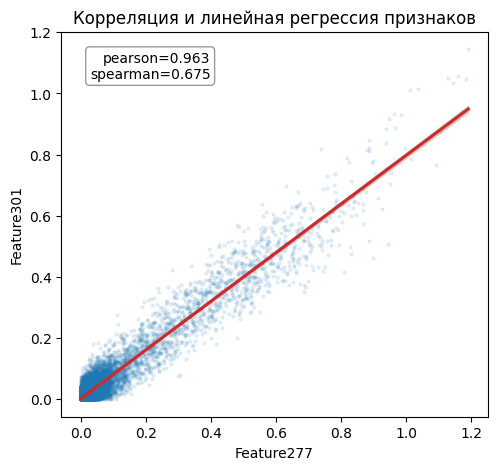

In [ ]:
CorrCleaner['vdc_type'].set_threshold(0.95).print_report()
CorrCleaner['vdc_type'].draw_cross_corr_diagram(frac=0.1);

## 1.5. Асимметрия признаков

In [ ]:
skew_stat = dict()
percentiles = np.arange(0.1, 1.0, 0.1)

skew_stat['efficientnet-b7'] = pd.Series(CorrCleaner['efficientnet-b7'].features_skew).describe(percentiles=percentiles)
skew_stat['efficientnet-b7'].name = 'efficientnet-b7'

skew_stat['osnet'] = pd.Series(CorrCleaner['osnet'].features_skew).describe(percentiles=percentiles)
skew_stat['osnet'].name = 'osnet'

skew_stat['vdc_color'] = pd.Series(CorrCleaner['vdc_color'].features_skew).describe(percentiles=percentiles)
skew_stat['vdc_color'].name = 'vdc_color'

skew_stat['vdc_type'] = pd.Series(CorrCleaner['vdc_type'].features_skew).describe(percentiles=percentiles)
skew_stat['vdc_type'].name = 'vdc_type'

# Статистика коэффициента скошенности
pd.concat(skew_stat.values(), axis=1)

,efficientnet-b7,osnet,vdc_color,vdc_type
count,2560.000000,511.000000,128.000000,512.000000
mean,1.164038,2.136119,-0.268114,1.661268
std,0.096619,1.801724,0.417944,1.415605
min,0.841458,-0.468645,-1.244387,-0.124847
10%,1.044222,0.563763,-0.770619,0.514703
20%,1.083203,0.805801,-0.492473,0.703422
30%,1.114910,1.052246,-0.434651,0.931241
40%,1.136971,1.323851,-0.380484,1.098531
50%,1.161492,1.638710,-0.321820,1.247385
60%,1.186399,1.999071,-0.271675,1.435147


## 1.6. Нулевые и отрицательные элемены

In [ ]:
# Наличие нулевых и отрицательных элементов
for name in data:
    print(f"{name:<18}Наличие нулей: {np.any(data[name]==0)},\tНаличие отрицательных элементов: {np.any(data[name]<0)}")

efficientnet-b7   Наличие нулей: True,	Наличие отрицательных элементов: True
osnet             Наличие нулей: True,	Наличие отрицательных элементов: False
vdc_color         Наличие нулей: False,	Наличие отрицательных элементов: True
vdc_type          Наличие нулей: True,	Наличие отрицательных элементов: False


In [ ]:
# Столбцы с отрицательными значениями
for name in data:
    zero_or_neg = np.any(data[name]<=0, axis=0)
    print(f"{name:<18}Столбцы с нулевыми и отрицательными элементами:  количество {zero_or_neg.sum()},\tдоля {zero_or_neg.mean():.1%}")

efficientnet-b7   Столбцы с нулевыми и отрицательными элементами:  количество 2560,	доля 100.0%
osnet             Столбцы с нулевыми и отрицательными элементами:  количество 511,	доля 99.8%
vdc_color         Столбцы с нулевыми и отрицательными элементами:  количество 128,	доля 100.0%
vdc_type          Столбцы с нулевыми и отрицательными элементами:  количество 512,	доля 100.0%


## 1.7. Итоги

In [ ]:
# Цикл очистки данных 

from sklearn.pipeline import Pipeline
def cleaning(X, deduplicate_axis=None, const_threshold=1e-3, const_method='cv', corr_threshold=0.9, corr_method='pearson'):
    clean_pipe = Pipeline(
        [
            ("deduplicate", DataSetDeduplicator(axis=deduplicate_axis)),  # Удалять только дублирующиеся столбцы
            ("drop_const_features", DataSetConstFeaturesEraser(threshold=const_threshold, method=const_method)),
            ("drop_collinear_features", DataSetCorrelationCleaner(threshold=corr_threshold, method=corr_method))
        ]
    )
    print()
    print('Размерность на входе:', X.shape)
    X_cleaned = clean_pipe.fit_transform(X)
    dbl_cnt = clean_pipe["deduplicate"].col_dupl_mask.sum()
    const_cnt = clean_pipe["drop_const_features"].constant_cv_mask.sum()
    corr_cnt = clean_pipe["drop_collinear_features"].drop_mask.sum()
    print(f'Дубликаты: {dbl_cnt:>3}, Константы: {const_cnt:>3}, Коллинеарность: {corr_cnt:>3}')
    print('Размерность на выходе:', X_cleaned.shape, end='\n\n')
    return X_cleaned

In [ ]:
# Дедупликация ТОЛЬКО для столбцов, чтобы получить результат для ВСЕХ объектов
clean_params = {
    "deduplicate_axis": 1,
    "corr_threshold": 0.9,
    "corr_method": 'spearman' # spearman pearson
}

%time efficientnet_cleaned = cleaning(data['efficientnet-b7'], **clean_params)
%time osnet_cleaned = cleaning(data['osnet'], **clean_params)
%time vdc_color_cleaned = cleaning(data['vdc_color'], **clean_params)
%time vdc_type_cleaned = cleaning(data['vdc_type'], **clean_params)


Размерность на входе: (416314, 2560)
Дубликаты:   0, Константы:   0, Коллинеарность:   0
Размерность на выходе: (416314, 2560)

CPU times: total: 11min 35s
Wall time: 6min 36s

Размерность на входе: (416314, 512)
Дубликаты:   0, Константы:   1, Коллинеарность:   0
Размерность на выходе: (416314, 511)

CPU times: total: 1min 6s
Wall time: 33.3 s

Размерность на входе: (416314, 128)
Дубликаты:   0, Константы:   0, Коллинеарность:   4
Размерность на выходе: (416314, 124)

CPU times: total: 12.7 s
Wall time: 9.99 s

Размерность на входе: (416314, 512)
Дубликаты:   0, Константы:   0, Коллинеарность: 116
Размерность на выходе: (416314, 396)

CPU times: total: 1min 13s
Wall time: 46.3 s


Пропусков в данных нет, бесконечностей нет. Дублирующиеся строки есть в osnet, vdc_color и vdc_type, причем набор дублей в этих дескрипторах одинаковый. Среди столбцов дублей нет. 

В osnet присутствует один константный признак, который не несет полезной информации. 

У распределений большинства признаков по всем дескрипторам, кроме vdc_color, преобладает умеренная скошенность вправо. Перед нормализацией рекомендуется предварительное нелинейное преобразование, но отрицательные значения ограничивают возможные варианты. Возможные варианты: RobustScaler, Yeo-Johnson, QuantileTransformer с параметром output_distribution='normal'.

Таким образом, формируются первые гиперпараметры модели, которые относятся к подготовке данных:

* Метод проверки константных признаков: ['std', 'cv'], можно оставить только cv
* Порог для признания признака константным: [1e-3]
* Метод проверки мультиколлинеарности: ['pearson', 'spearman']
* Порог корреляции: [0.90, 0.93, 0.95]
* Метод предобработки: RobustScaler, Yeo-Johnson, QuantileTransformer (normal), None

In [ ]:
# Сохранение очищенных датасетов
with open(os.path.join('temp', 'efficientnet_cleaned.pickle'), 'wb') as pkl_file:
    pickle.dump(efficientnet_cleaned, pkl_file)
    print(f'{"efficientnet_cleaned":<22}', efficientnet_cleaned.shape)

with open(os.path.join('temp', 'osnet_cleaned.pickle'), 'wb') as pkl_file:
    pickle.dump(osnet_cleaned, pkl_file)
    print(f'{"osnet_cleaned":<22}', osnet_cleaned.shape)

with open(os.path.join('temp', 'vdc_color_cleaned.pickle'), 'wb') as pkl_file:
    pickle.dump(vdc_color_cleaned, pkl_file)
    print(f'{"vdc_color_cleaned":<22}', vdc_color_cleaned.shape)

with open(os.path.join('temp', 'vdc_type_cleaned.pickle'), 'wb') as pkl_file:
    pickle.dump(vdc_type_cleaned, pkl_file)
    print(f'{"vdc_type_cleaned":<22}', vdc_type_cleaned.shape)

efficientnet_cleaned   (416314, 2560)
osnet_cleaned          (416314, 511)
vdc_color_cleaned      (416314, 124)
vdc_type_cleaned       (416314, 396)
